<a href="https://colab.research.google.com/github/nuwani2001/ITP_Project_HRM_System/blob/main/Vodafone%20customer%20churn%20project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Libraries

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# EDA

In [24]:
# The excel sheet is loaded into the drive manually
#Read data
df = pd.read_excel('/content/drive/MyDrive/customer churn data.xlsx')
df.head()

,customerID,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,numAdminTickets,numTechTickets,Churn,Location
0,7590-VHVEG,Female,0,No,1,No,No phone service,DSL,No,Yes,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,0.0,0,No,North - New York
1,5575-GNVDE,NaN,0,No,34,Yes,No,DSL,Yes,No,...,No,One year,No,Mailed check,56.95,1889.5,0.0,0,No,West - California
2,3668-QPYBK,Male,0,No,2,Yes,No,DSL,Yes,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,0.0,0,Yes,East - Illinois
3,7795-CFOCW,Male,0,No,45,No,No phone service,DSL,Yes,No,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,0.0,3,No,West - Illinois
4,9237-HQITU,Female,0,No,2,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,0.0,0,Yes,East - Illinois


In [25]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            6647 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       6616 non-null   object 
 13  StreamingMovies   6537 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [26]:
df.isnull().sum()


,0
customerID,0
gender,396
SeniorCitizen,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [27]:
numerical_columns = df.select_dtypes(include="number").columns.tolist()

print("Numerical variables:",numerical_columns)
print('count:',len(numerical_columns))

categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("\nCategorical variables:",categorical_columns)
print('count:',len(categorical_columns))

Numerical variables: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'numAdminTickets', 'numTechTickets']
count: 5

Categorical variables: ['customerID', 'gender', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn', 'Location']
count: 18


In [28]:
total_charges_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values after conversion:", total_charges_numeric.isnull().sum())

Missing values after conversion: 11


In [29]:
print("duplicates: ",df.duplicated().sum())

duplicates:  0


In [30]:
churn_counts = df['Churn'].value_counts()
print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [31]:
print("Churn percentages:\n",df["Churn"].value_counts(normalize=True) * 100)

Churn percentages:
 Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


#Visualizing churn distribution

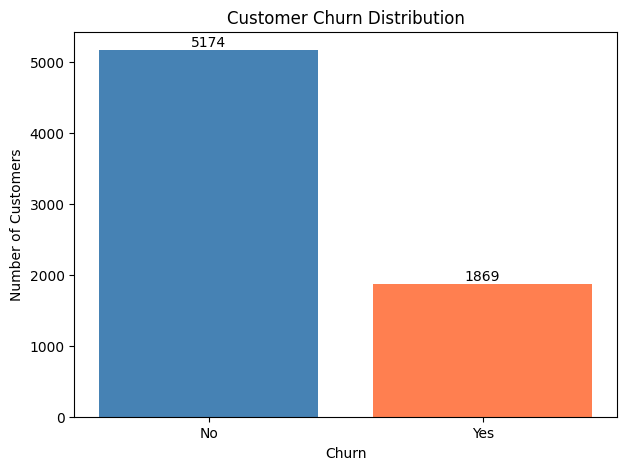

In [32]:
plt.figure(figsize=(7, 5))

plt.bar(
    churn_counts.index,
    churn_counts.values,
    color=["steelblue", "coral"]
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

# Add the number of customers above each bar
for i, count in enumerate(churn_counts.values):
    plt.text(i, count + 50, str(count), ha="center")

plt.show()

In [33]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isnull().sum())

Data type: float64
Missing values: 11


In [34]:
X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"].map({"No": 0, "Yes": 1})

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Shape of X: (7043, 21)
Shape of y: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (5634, 21)
Testing features: (1409, 21)

Training target distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64
